# CNN for MRI classification

Соревнование заключается в том, чтобы с нуля реализовать сверточную нейронную сеть (CNN) для решения задачи классификации МРТ-изображений на пять классов.

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, Subset, ConcatDataset, random_split

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import copy
from pathlib import Path
from PIL import Image

In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используемое устройство: {device}')
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(4)

Используемое устройство: cuda


## I. Dataset Exploration

Датасет `mri_classification_dataset` состоит из МРТ-изображений, разделенных на пять классов `class_0`-`class_4`. Имеются обучающая, валидационная и тестовая выборка без меток классов.


In [4]:
data_dir = Path('mri_classification_dataset')

train_dir = data_dir / 'train'
val_dir = data_dir / 'val'
test_dir = data_dir / 'test'

В рамках предобработки изображения переводятся в одноканальные размером 256 на 256 пикселей и преобразуются в тензоры.

In [5]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform)
val_dataset = datasets.ImageFolder(val_dir, transform=transform)

print('train:', len(train_dataset))
print('val:', len(val_dataset))

train: 1390
val: 298


In [6]:
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.paths = sorted(Path(root_dir).glob('*.jpg'))
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img_path = self.paths[idx]
        image = Image.open(img_path)
        if self.transform:
            image = self.transform(image)
        return image

test_dataset = TestDataset(test_dir, transform=transform)
print('test:', len(test_dataset))

test: 300


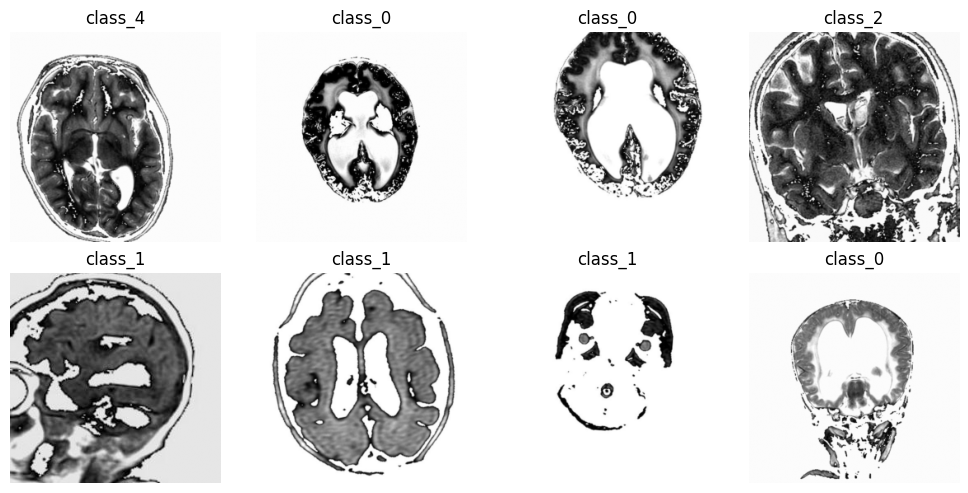

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
classes = train_dataset.classes

for i, ax in enumerate(axes.flat):
    idx = random.randint(0, len(train_dataset) - 1)
    img, label = train_dataset[idx]
    ax.imshow(img.permute(1, 2, 0).numpy(), cmap='gray')
    ax.set_title(classes[label])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [18]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## II. CNN Architecture

Для решения задачи используем CNN, состоящую из ести сверточных слоев, объединенных  четыре блока. CNN содержит `Conv2d` с ядром 3 × 3, `BatchNorm2d`, `ReLU` в качестве функции активации, `MaxPool2d`, `Dropout2d` для регуляризации, `AdaptiveAvgPool2d`.

In [9]:
class CNN(nn.Module):
    def __init__(self, num_classes=5, dropout=0.0):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.1),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.1),
        )

        self.fc_layers = nn.Sequential(
            nn.AdaptiveAvgPool2d(2),
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

In [ ]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

model = CNN(num_classes=5).to(device)
model

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ce

В качестве функции потерь используется `CrossEntropyLoss`, в качестве оптимизатора - `AdamW`.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

In [11]:
def train_model(
    model,
    criterion,
    optimizer,
    train_loader,
    val_loader,
    epochs=35,
    scheduler=None,
    patience=10,
    device=device
):
    train_loss_history = []
    val_loss_history = []
    train_acc_history = []
    val_acc_history = []
    best_acc = -1
    best_state = None
    best_epoch = 0
    best_val_loss = float('inf')
    early_stopping_counter = 0

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)

            preds = outputs.argmax(dim=1)
            train_correct += (preds == labels).sum().item()

        epoch_train_loss = train_loss / len(train_loader.dataset)
        epoch_train_acc = train_correct / len(train_loader.dataset)

        train_loss_history.append(epoch_train_loss)
        train_acc_history.append(epoch_train_acc)

        model.eval()
        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)

                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = val_correct / len(val_loader.dataset)

        if scheduler is not None:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(epoch_val_loss)
            else:
                scheduler.step()

        if epoch_val_acc > best_acc:
            best_acc = epoch_val_acc
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        val_loss_history.append(epoch_val_loss)
        val_acc_history.append(epoch_val_acc)

        print(f'Epoch {epoch+1}/{epochs}')
        print(f'Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f}')
        print(f'Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}')

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            early_stopping_counter = 0
        else:
            early_stopping_counter += 1

        if early_stopping_counter >= patience:
            print(f'Early stopping at epoch {epoch + 1}')
            break

    model.load_state_dict(best_state)
    print(f'Best epoch: {best_epoch+1}, Best val acc: {best_acc:.4f}')

    return train_loss_history, val_loss_history, train_acc_history, val_acc_history

In [ ]:
train_loss_history, val_loss_history, train_acc_history, val_acc_history = train_model(
    model,
    criterion,
    optimizer,
    train_loader,
    val_loader
)

Epoch 1/35
Train Loss: 1.2243, Train Acc: 0.5137
Val Loss: 1.9894, Val Acc: 0.3255
Epoch 2/35
Train Loss: 0.7519, Train Acc: 0.7331
Val Loss: 0.7442, Val Acc: 0.6946
Epoch 3/35
Train Loss: 0.5840, Train Acc: 0.7964
Val Loss: 0.6586, Val Acc: 0.7483
Epoch 4/35
Train Loss: 0.4886, Train Acc: 0.8295
Val Loss: 0.4214, Val Acc: 0.8658
Epoch 5/35
Train Loss: 0.4511, Train Acc: 0.8353
Val Loss: 1.6260, Val Acc: 0.4899
Epoch 6/35
Train Loss: 0.3316, Train Acc: 0.8906
Val Loss: 0.4165, Val Acc: 0.8289
Epoch 7/35
Train Loss: 0.3600, Train Acc: 0.8748
Val Loss: 0.3787, Val Acc: 0.8591
Epoch 8/35
Train Loss: 0.2566, Train Acc: 0.9230
Val Loss: 0.2743, Val Acc: 0.9027
Epoch 9/35
Train Loss: 0.2217, Train Acc: 0.9367
Val Loss: 0.3360, Val Acc: 0.8993
Epoch 10/35
Train Loss: 0.2229, Train Acc: 0.9353
Val Loss: 0.4888, Val Acc: 0.7852
Epoch 11/35
Train Loss: 0.1971, Train Acc: 0.9396
Val Loss: 0.2827, Val Acc: 0.8926
Epoch 12/35
Train Loss: 0.1341, Train Acc: 0.9633
Val Loss: 0.3976, Val Acc: 0.8154
E

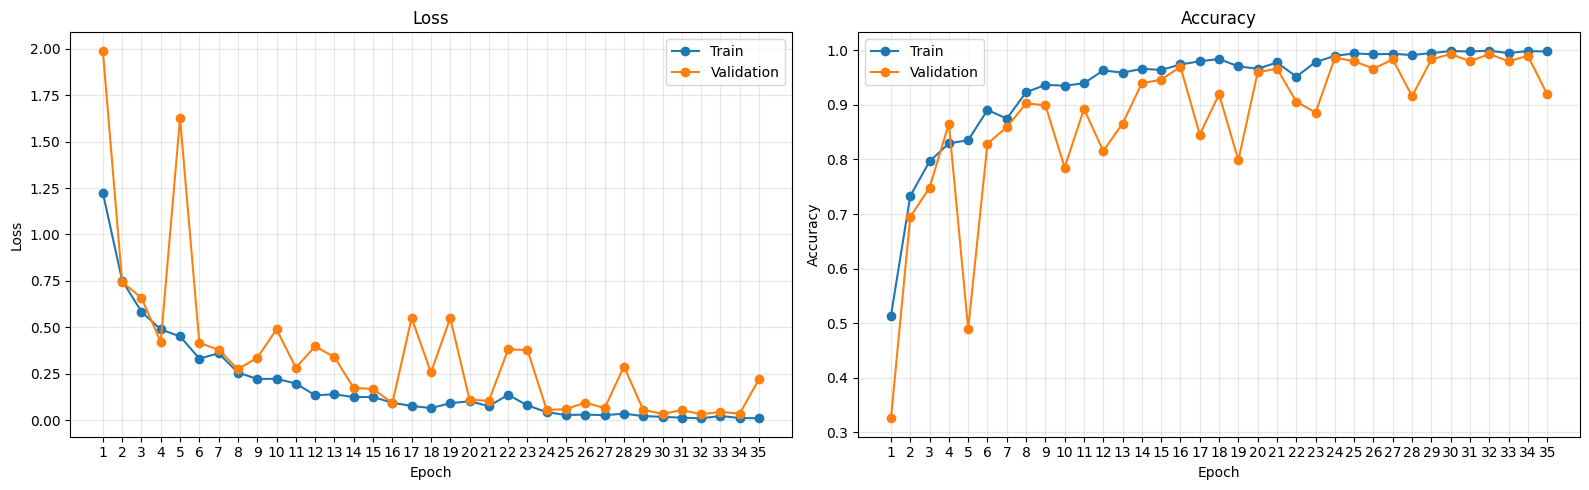

In [ ]:
epochs_range = range(1, len(train_loss_history) + 1)

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss_history, marker='o', label='Train')
plt.plot(epochs_range, val_loss_history, marker='o', label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc_history, marker='o', label='Train')
plt.plot(epochs_range, val_acc_history, marker='o', label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
best_epoch = np.argmax(val_acc_history)

results = [{
    'Name': 'Baseline',
    'Dropout': 0.0,
    'Augmentations': 'No',
    'Scheduler': 'No',
    'Best Epoch': best_epoch + 1,
    'Best Val Accuracy': max(val_acc_history),
    'Val Loss': val_loss_history[best_epoch],
    'Train Accuracy': train_acc_history[best_epoch]
}]

## III. Data Augmentation

Для повышения устойчивости модели к изменениям входных изображений применим аугментации к обучающей выборке. Используем следующие преобразования:

* Случайный поворот до 10°.
* Случайное смещение до 5%.
* Масштабирование в диапазоне 0.9-1.1.
* Случайное изменение яркости и контрастности на 10%.

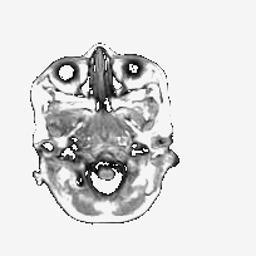

In [13]:
img_tensor, _ = train_dataset[0]
img_pil = transforms.ToPILImage()(img_tensor)
img_pil

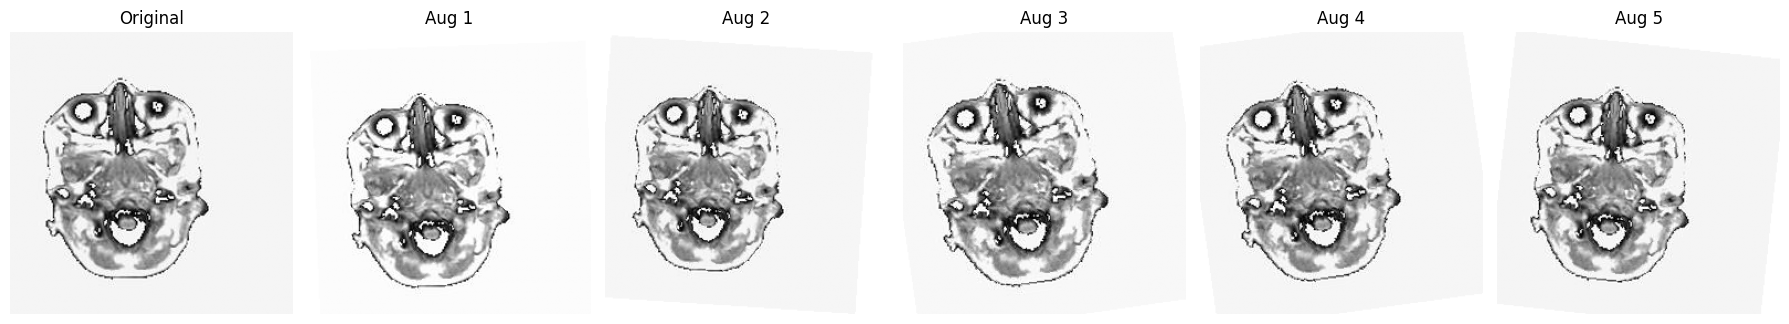

In [14]:
aug_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((256, 256)),
        transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10),
        fill=255
    ),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
])

fig, axes = plt.subplots(1, 6, figsize=(18, 4))
axes[0].imshow(img_pil, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

for i in range(1, 6):
    aug_img = aug_transform(img_pil)
    axes[i].imshow(aug_img.permute(1, 2, 0).numpy(), cmap='gray')
    axes[i].set_title(f'Aug {i}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [19]:
aug_train_dataset = datasets.ImageFolder(train_dir, transform=aug_transform)
aug_train_loader = DataLoader(aug_train_dataset, batch_size=BATCH_SIZE, shuffle=True)

In [ ]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

aug_model = CNN(num_classes=5).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_aug = optim.AdamW(aug_model.parameters(), lr=3e-4, weight_decay=1e-4)

In [ ]:
aug_train_loss_history, aug_val_loss_history, aug_train_acc_history, aug_val_acc_history = train_model(
    aug_model,
    criterion,
    optimizer_aug,
    aug_train_loader,
    val_loader
)

Epoch 1/35
Train Loss: 1.2503, Train Acc: 0.5036
Val Loss: 2.6042, Val Acc: 0.2785
Epoch 2/35
Train Loss: 0.7920, Train Acc: 0.7151
Val Loss: 0.7362, Val Acc: 0.7282
Epoch 3/35
Train Loss: 0.6447, Train Acc: 0.7734
Val Loss: 1.0548, Val Acc: 0.5940
Epoch 4/35
Train Loss: 0.5631, Train Acc: 0.7942
Val Loss: 1.4938, Val Acc: 0.5000
Epoch 5/35
Train Loss: 0.4826, Train Acc: 0.8194
Val Loss: 0.6599, Val Acc: 0.7685
Epoch 6/35
Train Loss: 0.4602, Train Acc: 0.8309
Val Loss: 0.4934, Val Acc: 0.7718
Epoch 7/35
Train Loss: 0.3740, Train Acc: 0.8727
Val Loss: 0.5582, Val Acc: 0.7617
Epoch 8/35
Train Loss: 0.4186, Train Acc: 0.8410
Val Loss: 0.4786, Val Acc: 0.8289
Epoch 9/35
Train Loss: 0.3086, Train Acc: 0.8906
Val Loss: 0.2899, Val Acc: 0.9060
Epoch 10/35
Train Loss: 0.2909, Train Acc: 0.8978
Val Loss: 0.2173, Val Acc: 0.9396
Epoch 11/35
Train Loss: 0.2734, Train Acc: 0.9043
Val Loss: 0.2263, Val Acc: 0.9430
Epoch 12/35
Train Loss: 0.2228, Train Acc: 0.9266
Val Loss: 0.1556, Val Acc: 0.9631
E

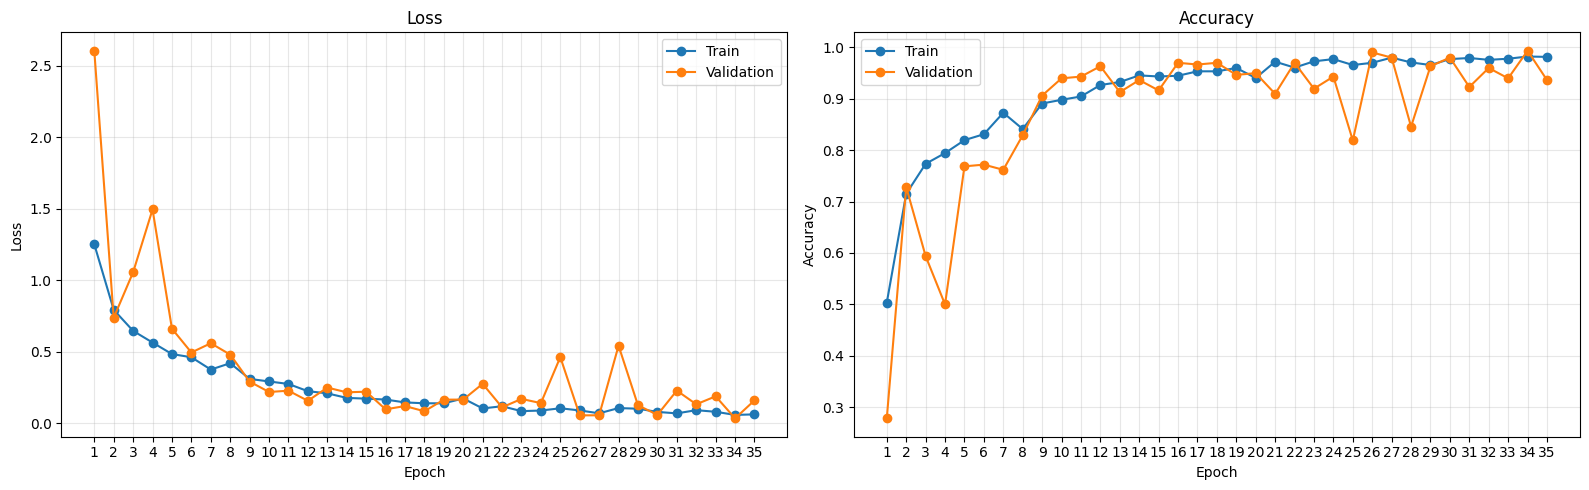

In [ ]:
epochs_range = range(1, len(aug_train_loss_history) + 1)

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, aug_train_loss_history, marker='o', label='Train')
plt.plot(epochs_range, aug_val_loss_history, marker='o', label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, aug_train_acc_history, marker='o', label='Train')
plt.plot(epochs_range, aug_val_acc_history, marker='o', label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
best_epoch = np.argmax(aug_val_acc_history)

results.append({
    'Name': 'Augmented',
    'Dropout': 0.0,
    'Augmentations': 'Yes',
    'Scheduler': 'No',
    'Best Epoch': best_epoch + 1,
    'Best Val Accuracy': max(aug_val_acc_history),
    'Val Loss': aug_val_loss_history[best_epoch],
    'Train Accuracy': aug_train_acc_history[best_epoch]
})

In [ ]:
results_df = pd.DataFrame(results)
results_df.sort_values('Best Val Accuracy', ascending=False)

,Name,Dropout,Augmentations,Scheduler,Best Epoch,Best Val Accuracy,Val Loss,Train Accuracy
0,Baseline,0.0,No,No,30,0.993289,0.034071,0.998561
1,Augmented,0.0,Yes,No,34,0.993289,0.032933,0.982014


## IV. Dropout Experiments

Проведем эксперимент влияния регуляризации (`Dropout`) в полносвязной части сети.

In [ ]:
dropouts = [0.2, 0.3, 0.5]

best_acc = -1
best_history = None

for dropout in dropouts:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model_ = CNN(num_classes=5, dropout=dropout).to(device)
    criterion_ = nn.CrossEntropyLoss()
    optimizer_ = optim.AdamW(model_.parameters(), lr=3e-4, weight_decay=1e-4)

    print('-' * 70)
    print(f'dropout={dropout}')
    print('-' * 70)

    train_loss_history_, val_loss_history_, train_acc_history_, val_acc_history_ = train_model(
        model_,
        criterion_,
        optimizer_,
        aug_train_loader,
        val_loader
    )

    if best_acc < max(val_acc_history_):
        best_acc = max(val_acc_history_)
        best_history = (
            train_loss_history_, val_loss_history_, train_acc_history_, val_acc_history_
        )

    best_epoch = np.argmax(val_acc_history_)

    results.append({
        'Name': f'dropout={dropout}',
        'Dropout': dropout,
        'Augmentations': 'Yes',
        'Scheduler': 'No',
        'Best Epoch': best_epoch + 1,
        'Best Val Accuracy': max(val_acc_history_),
        'Val Loss': val_loss_history_[best_epoch],
        'Train Accuracy': train_acc_history_[best_epoch]
    })

results_df = pd.DataFrame(results)
results_df.sort_values('Best Val Accuracy', ascending=False)

----------------------------------------------------------------------
dropout=0.2
----------------------------------------------------------------------
Epoch 1/35
Train Loss: 1.2795, Train Acc: 0.4799
Val Loss: 2.0257, Val Acc: 0.3188
Epoch 2/35
Train Loss: 0.8321, Train Acc: 0.6978
Val Loss: 1.0357, Val Acc: 0.5805
Epoch 3/35
Train Loss: 0.6956, Train Acc: 0.7388
Val Loss: 1.4367, Val Acc: 0.4765
Epoch 4/35
Train Loss: 0.6054, Train Acc: 0.7770
Val Loss: 0.4768, Val Acc: 0.8322
Epoch 5/35
Train Loss: 0.5317, Train Acc: 0.8086
Val Loss: 0.6151, Val Acc: 0.7550
Epoch 6/35
Train Loss: 0.4546, Train Acc: 0.8475
Val Loss: 0.4747, Val Acc: 0.8389
Epoch 7/35
Train Loss: 0.4178, Train Acc: 0.8453
Val Loss: 1.9571, Val Acc: 0.4564
Epoch 8/35
Train Loss: 0.4209, Train Acc: 0.8424
Val Loss: 0.6161, Val Acc: 0.7953
Epoch 9/35
Train Loss: 0.3349, Train Acc: 0.8770
Val Loss: 0.3747, Val Acc: 0.8591
Epoch 10/35
Train Loss: 0.3196, Train Acc: 0.8820
Val Loss: 0.3445, Val Acc: 0.8758
Epoch 11/35
Tra

,Name,Dropout,Augmentations,Scheduler,Best Epoch,Best Val Accuracy,Val Loss,Train Accuracy
0,Baseline,0.0,No,No,30,0.993289,0.034071,0.998561
1,Augmented,0.0,Yes,No,34,0.993289,0.032933,0.982014
2,dropout=0.2,0.2,Yes,No,29,0.986577,0.057201,0.946043
3,dropout=0.3,0.3,Yes,No,33,0.983221,0.080451,0.961151
4,dropout=0.5,0.5,Yes,No,24,0.983221,0.097999,0.933813


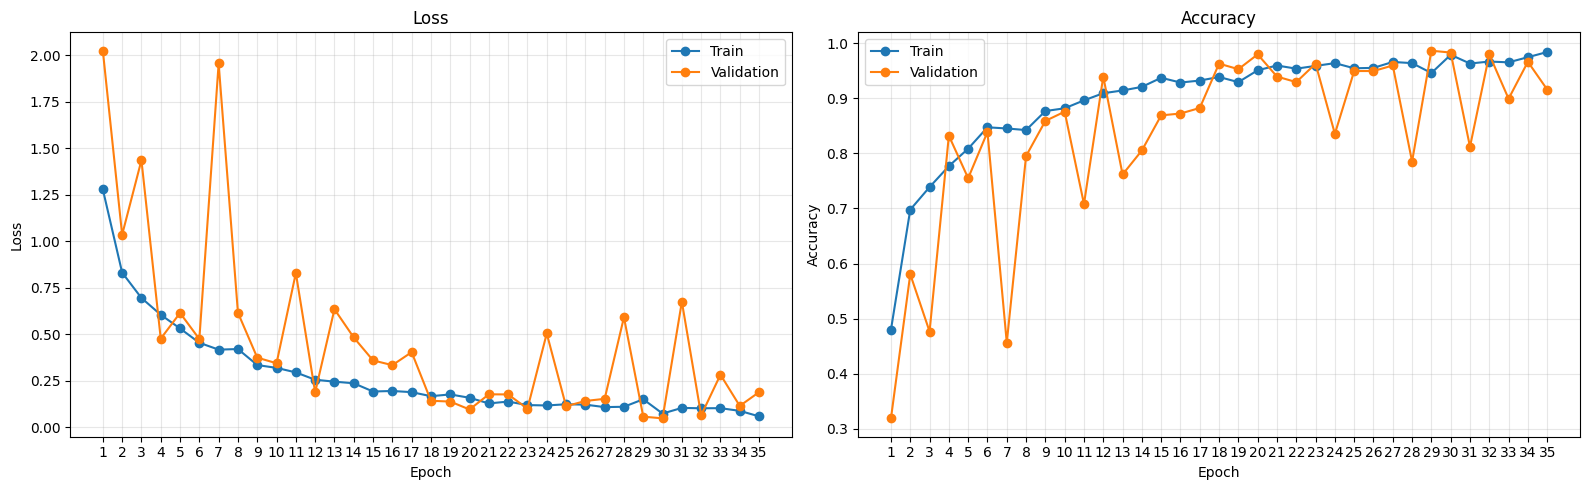

In [ ]:
do_train_loss_history, do_val_loss_history, do_train_acc_history, do_val_acc_history = best_history

epochs_range = range(1, len(do_train_loss_history) + 1)

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, do_train_loss_history, marker='o', label='Train')
plt.plot(epochs_range, do_val_loss_history, marker='o', label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, do_train_acc_history, marker='o', label='Train')
plt.plot(epochs_range, do_val_acc_history, marker='o', label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## V. Learning Rate Scheduler Experiments

Аналогично, проведем эксперимент для исследования влияния изменения скорости обучения добавим и сравним три вида планировщика.

In [ ]:
scheduler_configs = [
    ('Plateau p=3 f=0.5', 'plateau', {'patience': 3, 'factor': 0.5}),
    ('Plateau p=5 f=0.5', 'plateau', {'patience': 5, 'factor': 0.5}),
    ('Cosine T=35 min=1e-6', 'cosine', {'T_max': 35, 'eta_min': 1e-6}),
]

best_acc = -1
best_history = None

for name, scheduler_type, params in scheduler_configs:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model_ = CNN(num_classes=5, dropout=0.3).to(device)
    criterion_ = nn.CrossEntropyLoss()
    optimizer_ = optim.AdamW(model_.parameters(), lr=3e-4, weight_decay=1e-4)

    if scheduler_type == 'plateau':
        scheduler_ = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer_,
            mode='min',
            min_lr=1e-6,
            **params
        )
    else:
        scheduler_ = optim.lr_scheduler.CosineAnnealingLR(
            optimizer_,
            **params
        )

    print('-' * 70)
    print(name)
    print('-' * 70)

    train_loss_history_, val_loss_history_, train_acc_history_, val_acc_history_ = train_model(
        model_,
        criterion_,
        optimizer_,
        aug_train_loader,
        val_loader,
        scheduler=scheduler_
    )

    best_epoch = np.argmax(val_acc_history_)

    if best_acc < max(val_acc_history_):
        best_acc = max(val_acc_history_)
        best_history = (
            train_loss_history_, val_loss_history_, train_acc_history_, val_acc_history_
        )

    results.append({
        'Name': name,
        'Dropout': 0.3,
        'Augmentations': 'Yes',
        'Scheduler': scheduler_,
        'Best Epoch': best_epoch + 1,
        'Best Val Accuracy': max(val_acc_history_),
        'Val Loss': val_loss_history_[best_epoch],
        'Train Accuracy': train_acc_history_[best_epoch]
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values('Best Val Accuracy', ascending=False))

----------------------------------------------------------------------
Plateau p=3 f=0.5
----------------------------------------------------------------------
Epoch 1/35
Train Loss: 1.3104, Train Acc: 0.4683
Val Loss: 2.5631, Val Acc: 0.2886
Epoch 2/35
Train Loss: 0.8908, Train Acc: 0.6741
Val Loss: 0.9836, Val Acc: 0.5872
Epoch 3/35
Train Loss: 0.7200, Train Acc: 0.7345
Val Loss: 1.9498, Val Acc: 0.3826
Epoch 4/35
Train Loss: 0.6326, Train Acc: 0.7748
Val Loss: 1.0188, Val Acc: 0.6007
Epoch 5/35
Train Loss: 0.5494, Train Acc: 0.8022
Val Loss: 0.4249, Val Acc: 0.8523
Epoch 6/35
Train Loss: 0.4774, Train Acc: 0.8288
Val Loss: 0.5182, Val Acc: 0.8087
Epoch 7/35
Train Loss: 0.4465, Train Acc: 0.8374
Val Loss: 1.0080, Val Acc: 0.5940
Epoch 8/35
Train Loss: 0.4537, Train Acc: 0.8259
Val Loss: 0.5907, Val Acc: 0.7953
Epoch 9/35
Train Loss: 0.3968, Train Acc: 0.8547
Val Loss: 0.2698, Val Acc: 0.9060
Epoch 10/35
Train Loss: 0.3404, Train Acc: 0.8799
Val Loss: 0.2716, Val Acc: 0.9027
Epoch 11/

,Name,Dropout,Augmentations,Scheduler,Best Epoch,Best Val Accuracy,Val Loss,Train Accuracy
7,Cosine T=35 min=1e-6,0.3,Yes,<torch.optim.lr_scheduler.CosineAnnealingLR ob...,30,1.000000,0.041303,0.977698
5,Plateau p=3 f=0.5,0.3,Yes,<torch.optim.lr_scheduler.ReduceLROnPlateau ob...,29,0.996644,0.035778,0.964748
0,Baseline,0.0,No,No,30,0.993289,0.034071,0.998561
1,Augmented,0.0,Yes,No,34,0.993289,0.032933,0.982014
6,Plateau p=5 f=0.5,0.3,Yes,<torch.optim.lr_scheduler.ReduceLROnPlateau ob...,34,0.989933,0.040367,0.977698
2,dropout=0.2,0.2,Yes,No,29,0.986577,0.057201,0.946043
3,dropout=0.3,0.3,Yes,No,33,0.983221,0.080451,0.961151
4,dropout=0.5,0.5,Yes,No,24,0.983221,0.097999,0.933813


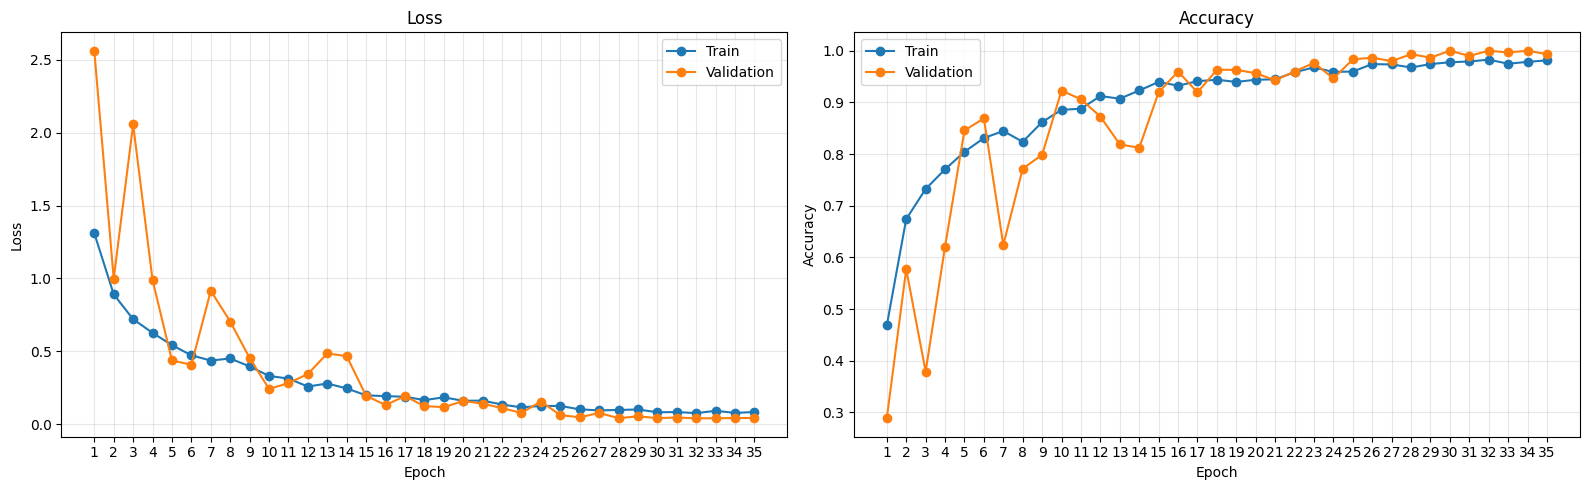

In [ ]:
sch_train_loss_history, sch_val_loss_history, sch_train_acc_history, sch_val_acc_history = best_history

epochs_range = range(1, len(sch_train_loss_history) + 1)

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, sch_train_loss_history, marker='o', label='Train')
plt.plot(epochs_range, sch_val_loss_history, marker='o', label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, sch_train_acc_history, marker='o', label='Train')
plt.plot(epochs_range, sch_val_acc_history, marker='o', label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.xticks(epochs_range)
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## VI. Final Model Training

In [29]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

model = CNN(num_classes=5, dropout=0.3).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=35,
    eta_min=1e-6
)

train_loss_history, val_loss_history, train_acc_history, val_acc_history = train_model(
    model,
    criterion,
    optimizer,
    aug_train_loader,
    val_loader,
    epochs=35,
    scheduler=scheduler
)

Epoch 1/35
Train Loss: 1.3104, Train Acc: 0.4683
Val Loss: 2.5631, Val Acc: 0.2886
Epoch 2/35
Train Loss: 0.8910, Train Acc: 0.6741
Val Loss: 0.9981, Val Acc: 0.5772
Epoch 3/35
Train Loss: 0.7201, Train Acc: 0.7324
Val Loss: 2.0578, Val Acc: 0.3792
Epoch 4/35
Train Loss: 0.6268, Train Acc: 0.7705
Val Loss: 0.9897, Val Acc: 0.6208
Epoch 5/35
Train Loss: 0.5426, Train Acc: 0.8043
Val Loss: 0.4371, Val Acc: 0.8456
Epoch 6/35
Train Loss: 0.4723, Train Acc: 0.8309
Val Loss: 0.4080, Val Acc: 0.8691
Epoch 7/35
Train Loss: 0.4366, Train Acc: 0.8446
Val Loss: 0.9153, Val Acc: 0.6242
Epoch 8/35
Train Loss: 0.4508, Train Acc: 0.8237
Val Loss: 0.7043, Val Acc: 0.7718
Epoch 9/35
Train Loss: 0.3958, Train Acc: 0.8619
Val Loss: 0.4535, Val Acc: 0.7987
Epoch 10/35
Train Loss: 0.3310, Train Acc: 0.8856
Val Loss: 0.2418, Val Acc: 0.9228
Epoch 11/35
Train Loss: 0.3125, Train Acc: 0.8878
Val Loss: 0.2816, Val Acc: 0.9060
Epoch 12/35
Train Loss: 0.2582, Train Acc: 0.9122
Val Loss: 0.3438, Val Acc: 0.8725
E

## VII. Test-Time Augmentation (TTA)

Для получения предсказаний на тестовой выборке применяется Test-Time Augmentation (TTA). Используем аугментации и на этапе предсказания. Для каждого тестового изображения делаем 10 случайных преобразований, получаем предсказания для каждого варианта и усредняем вероятности. Это уменьшает случайную ошибку и повышает точность.

Используем следующие преобразования:

* Случайный поворот до 5°.
* Случайное смещение до 3%.
* Масштабирование в диапазоне 0.95-1.05.

In [33]:
tta_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=5,
        translate=(0.03, 0.03),
        scale=(0.95, 1.05),
        fill=1
    )
])

In [34]:
torch.manual_seed(seed)

n_tta = 10
test_preds = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        all_probs = []
        all_probs.append(torch.softmax(model(images), dim=1))

        for _ in range(n_tta):
            aug_images = torch.stack([tta_transform(img) for img in images])
            all_probs.append(torch.softmax(model(aug_images), dim=1))

        mean_probs = torch.stack(all_probs).mean(dim=0)
        preds = mean_probs.argmax(dim=1)
        test_preds.extend(preds.cpu().numpy())

test_preds = np.array(test_preds)

## VIII. Submission.csv

На основе предсказаний финальной модели на тестовой выборке формируется CSV-файл.

Файл содержит два столбца:

* `id` - идентификатор изображения;
* `label` - предсказанный класс.

In [35]:
submission = pd.DataFrame({
    'id': [Path(p).stem for p in test_dataset.paths],
    'label': [p for p in test_preds]
})

submission.to_csv('submission.csv', index=False)

Результат на тестовой выборке - 100%:
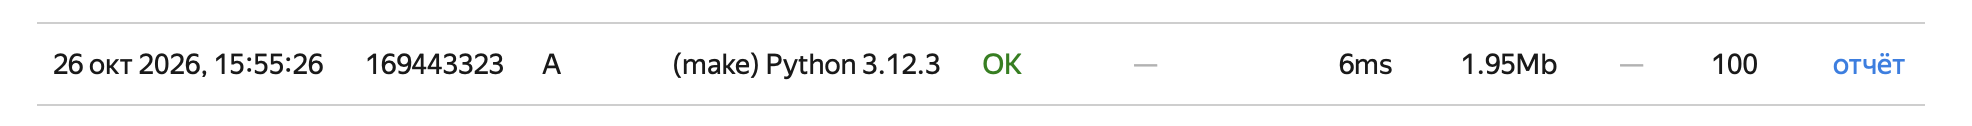